# Mapa inverso aprendido y prueba

**Nivel 1 — Fundamentos**  
**Prerrequisitos:** nociones de Python; 35 min.

## Objetivos

Siga la evidencia desde el contrato fuente hasta el resultado. Declare unidades y supuestos, reproduzca el cálculo e identifique qué inferencia no respalda la evidencia.

## Preparación

Usa módulos y registros versionados desde la raíz descubierta; no descarga ni modifica fuentes. Instale versiones exactas: `pip install numpy==2.2.6 matplotlib==3.10.8`

## Datos

El ledger guarda particiones, errores normalizados, métricas y evaluación OOD separada.

## Método

M12 predice columna de densidad integrada en profundidad desde entradas gravimétricas; no es modelo 3D. Ledger: 800/160/160 realizaciones train/validación/prueba, semillas disjuntas y geometrías oblicuas/anulares retenidas fuera del entrenamiento. Baseline clásico y CNN comparten 160 pruebas. MSE guardado: 1466,24 y 680,15 `(g·cm⁻³·m)²`. Reconstruya errores pareados CNN usando escala objetivo al cuadrado, grafique comparación y diferencia, e informe fracción mejorada y ganancia mediana. Evalúa un generador sintético y su partición, no geología de campo, cambios de adquisición ni calibración de incertidumbre; el promedio puede ocultar regresiones.

Errores pareados controlan dificultad, pero 160 realizaciones muestrean el generador, no geología natural independiente. Errores CNN están normalizados y requieren escala objetivo² para MSE físico. Separe por realización para evitar fuga; otro sitio/sensor es una prueba de transferencia más fuerte. No elija umbral OOD usando etiquetas OOD.

## Resultados

Lea ejes físicos y unidades; distinga ajuste, error contra verdad sintética y acuerdo con etiquetas humanas. El recálculo debe concordar con el recibo. Un modelo graficado no demuestra unicidad, transferencia a campo ni resolución.

### Diagnostic 1

Inspeccione el recibo y procedencia del caso.

In [1]:
from pathlib import Path
from importlib.metadata import version
print("Runtime versions:", {name: version(name) for name in ['numpy', 'matplotlib']})
import numpy as np
root=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/"data").is_dir() and (p/"data-pipeline").is_dir())
# Load paired test errors and undo the ledger's declared CNN target normalization.
import json
from pathlib import Path
d=json.loads((root/"data/derived/v2/models/training.json").read_text(encoding="utf-8")); a=np.asarray(d["classical_test_errors"],float); b=np.asarray(d["models"]["cnn"]["test_errors"],float)*d["target_scale"]**2
print("splits",d["split_counts"],d["split_policy"],"cases",len(a),"unit",d["units"],"stored MSE",d["classical_test_mse"],d["cnn_test_mse"],"recomputed",a.mean(),b.mean())

Runtime versions: {'numpy': '2.2.6', 'matplotlib': '3.10.8'}
splits [800, 160, 160] Disjoint generator seeds; complete realization assigned to one split; oblique and ring geometries withheld from training cases 160 unit (g/cm³ m)² stored MSE 1441.3277421693122 755.7566463947296 recomputed 1441.3277421693124 755.7565736933611


### Diagnostic 2

Calcule la comparación y grafíquela con unidades físicas.

CNN better fraction 0.79375 median gain 469.33024381926634 (g/cm³ m)²


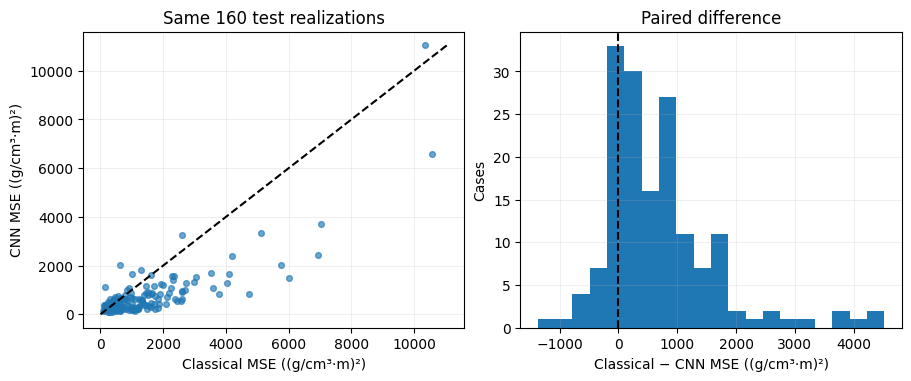

In [2]:
import numpy as np
import matplotlib.pyplot as plt
# Compare paired errors; points below the diagonal are cases where CNN MSE is lower.
import matplotlib.pyplot as plt
delta=a-b; lim=max(a.max(),b.max()); fig,ax=plt.subplots(1,2,figsize=(9,3.7),constrained_layout=True); ax[0].scatter(a,b,s=17,alpha=.65); ax[0].plot([0,lim],[0,lim],"k--"); ax[0].set(xlabel="Classical MSE ((g/cm³·m)²)",ylabel="CNN MSE ((g/cm³·m)²)",title="Same 160 test realizations"); ax[1].hist(delta,bins=20); ax[1].axvline(0,color="black",ls="--"); ax[1].set(xlabel="Classical − CNN MSE ((g/cm³·m)²)",ylabel="Cases",title="Paired difference"); [x.grid(alpha=.2) for x in ax]; print("CNN better fraction",(delta>0).mean(),"median gain",np.median(delta),d["units"]); plt.show()

## Resumen

La conclusión depende de geometría, adquisición, ruido, partición, parametrización y derechos de fuente. Conserve negativos y nombre la observación o control siguiente.

## Referencias

- [https://doi.org/10.1093/gji/ggy423](https://doi.org/10.1093/gji/ggy423)
- [https://github.com/AI4EPS/PhaseNet](https://github.com/AI4EPS/PhaseNet)
- [https://github.com/lanl/OpenFWI](https://github.com/lanl/OpenFWI)